<center><h1>Xiao_Hongwei_HW2</h1></center>

Name: Hongwei Xiao
<br>
Github Username: Ga9a

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from itertools import combinations
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import mean_squared_error


Get the Cycle Power Plant Data Set

In [2]:
df = pd.read_excel(
    "../data/CCPP/Folds5x2_pp.xlsx",
    sheet_name=0
)

df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### (b) Exploring the data

#### i. rows and columns

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9568
Number of columns: 5


The dataset has 9,568 rows and 5 columns. Each row contains hourly average measurements from the power plant while it was operating at full load.

Four columns are predictors: temperature (AT), exhaust vacuum (V), ambient pressure (AP), and relative humidity (RH). The remaining column, PE, is the electrical energy output we want to predict.

#### ii. pairwise scatterplots of all the varianbles

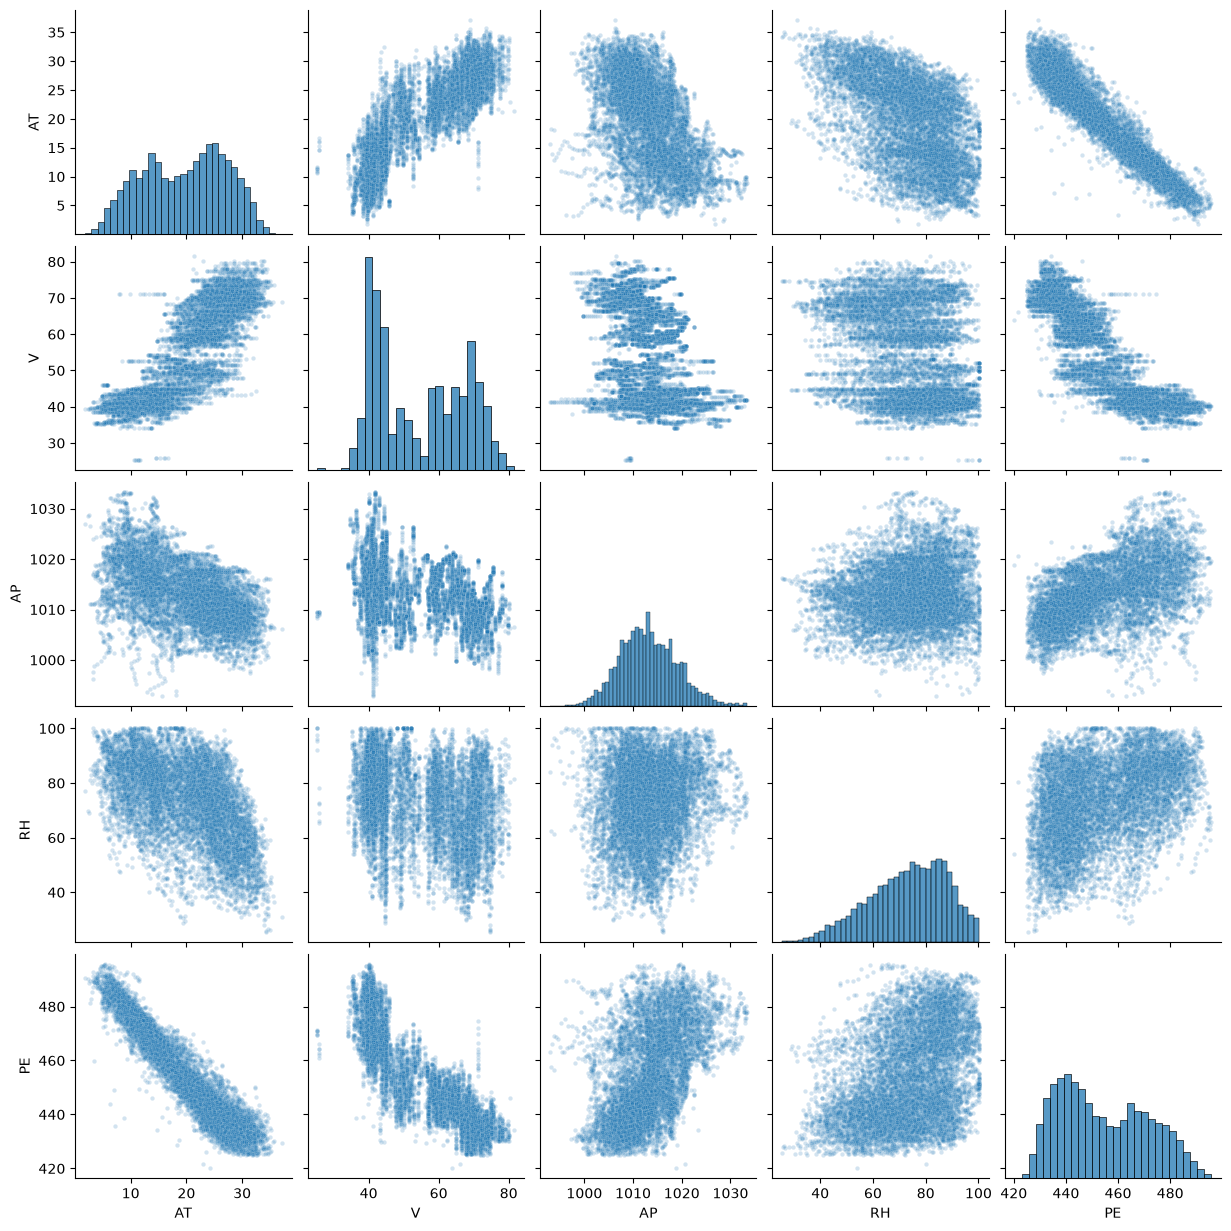

In [4]:
sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"alpha": 0.2, "s": 10}
)

plt.show()

AT has the clearest relationship with PE. As temperature increases, electrical output tends to decrease, and the points follow a fairly tight downward pattern. V also shows a negative relationship with PE, but the points are more spread out.

PE generally increases with AP and RH, although these relationships are weaker. Among the predictors, AT and V have a strong positive relationship, while AT tends to decrease as AP or RH increases. These relationships between predictors may help explain why the regression coefficients change when we fit them together.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [5]:
summary_stats = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
})

summary_stats.round(3)

,Mean,Median,Range,Q1,Q3,IQR
AT,19.651,20.345,35.30,13.510,25.72,12.210
V,54.306,52.080,56.20,41.740,66.54,24.800
AP,1013.259,1012.940,40.41,1009.100,1017.26,8.160
RH,73.309,74.975,74.60,63.328,84.83,21.502
PE,454.365,451.550,75.50,439.750,468.43,28.680


Range is calculated as the maximum minus the minimum, and IQR is calculated as Q3 minus Q1.

### (c) Simple Linear Regression

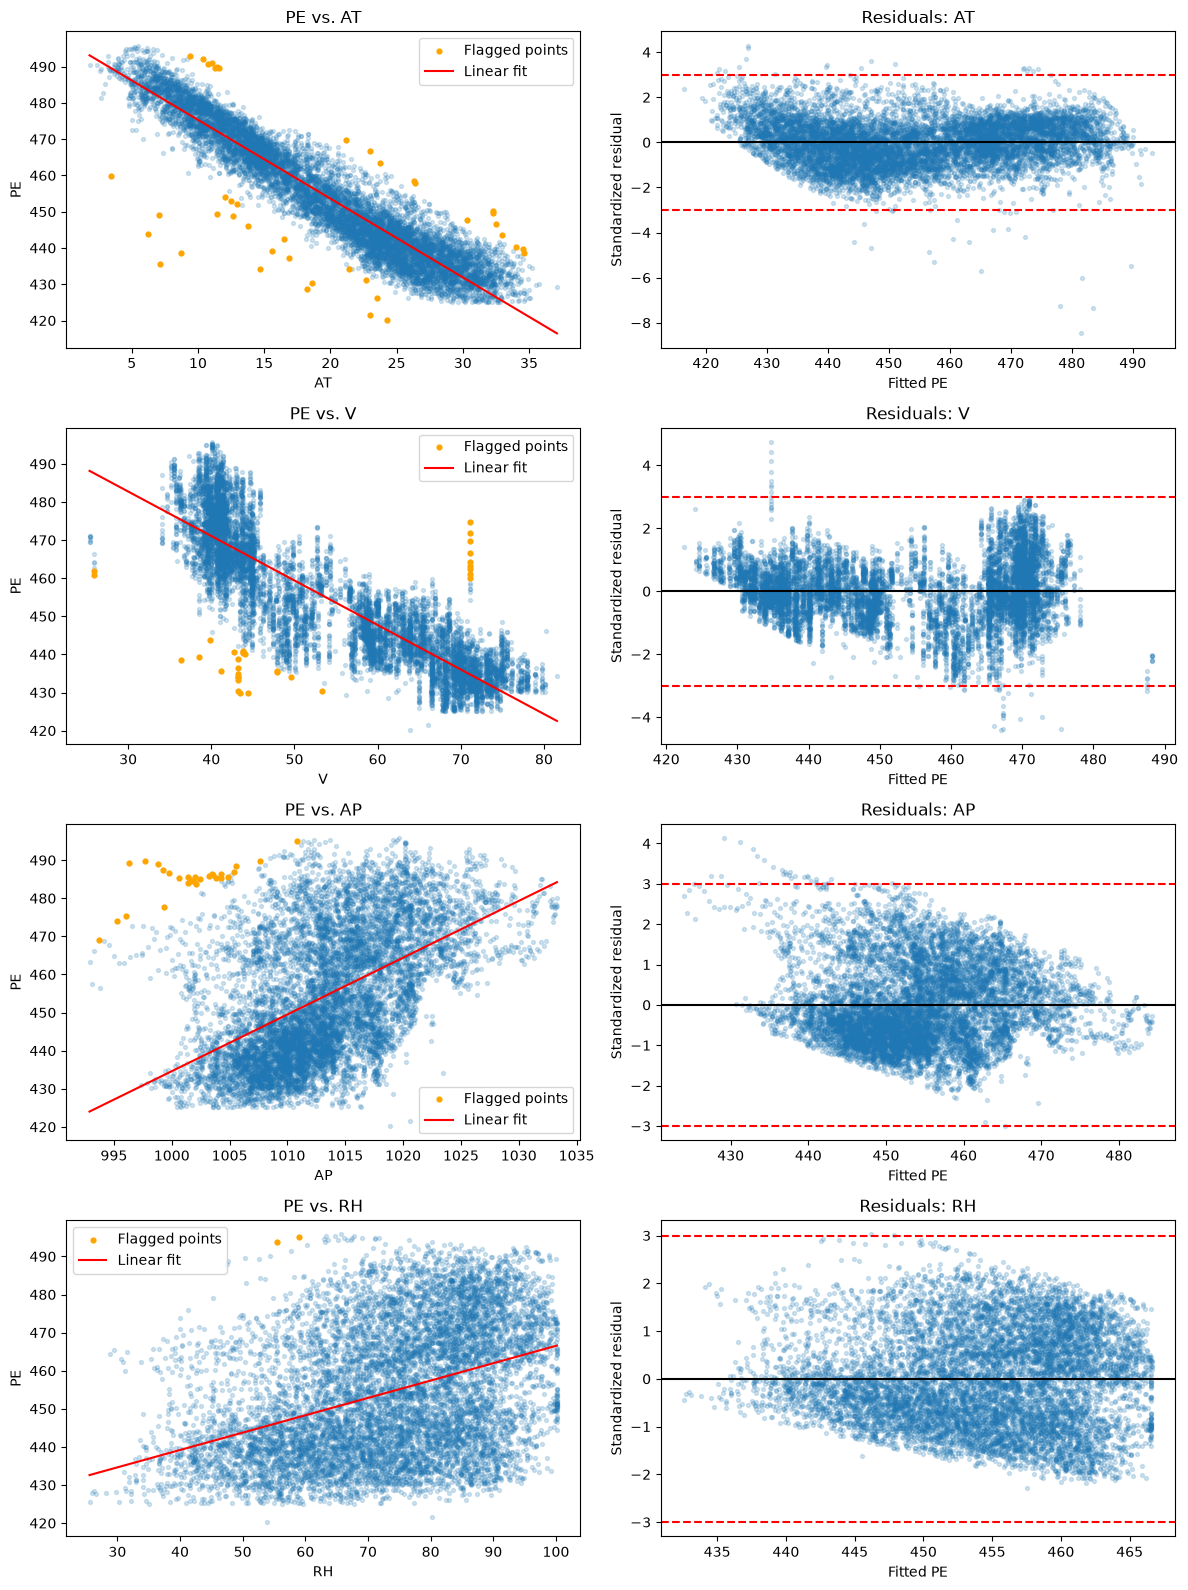

,Intercept,Coefficient,p-value,R-squared,Flagged points
Predictor,,,,,
AT,497.034120,-2.171320,0.0,0.898948,42
V,517.801526,-1.168135,0.0,0.756518,33
AP,-1055.260989,1.489872,0.0,0.268769,29
RH,420.961766,0.455650,0.0,0.151939,2


In [6]:
features = ["AT", "V", "AP", "RH"]
simple_models = {}
results = []

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, feature in enumerate(features):
    model = smf.ols(f"PE ~ {feature}", data=df).fit()
    simple_models[feature] = model

    residuals = model.get_influence().resid_studentized_internal
    flagged = np.abs(residuals) > 3

    results.append({
        "Predictor": feature,
        "Intercept": model.params["Intercept"],
        "Coefficient": model.params[feature],
        "p-value": model.pvalues[feature],
        "R-squared": model.rsquared,
        "Flagged points": flagged.sum()
    })

    # Scatterplot and fitted regression line
    ax = axes[i, 0]
    ax.scatter(df[feature], df["PE"], s=8, alpha=0.2)
    ax.scatter(
        df.loc[flagged, feature],
        df.loc[flagged, "PE"],
        s=12, color="orange", label="Flagged points"
    )

    x_grid = np.linspace(df[feature].min(), df[feature].max(), 200)
    predictions = model.predict(pd.DataFrame({feature: x_grid}))

    ax.plot(x_grid, predictions, color="red", label="Linear fit")
    ax.set(xlabel=feature, ylabel="PE", title=f"PE vs. {feature}")
    ax.legend()

    # Standardized residual plot
    ax = axes[i, 1]
    ax.scatter(model.fittedvalues, residuals, s=8, alpha=0.2)
    ax.axhline(0, color="black")
    ax.axhline(3, color="red", linestyle="--")
    ax.axhline(-3, color="red", linestyle="--")
    ax.set(
        xlabel="Fitted PE",
        ylabel="Standardized residual",
        title=f"Residuals: {feature}"
    )

plt.tight_layout()
plt.show()

simple_results = pd.DataFrame(results).set_index("Predictor")
display(simple_results)

All four simple regression slopes are significant at the 0.05 level. Their p-values are so small that the output displays them as 0.0; this does not mean they are exactly zero. The slopes are -2.171 for AT, -1.168 for V, 1.490 for AP, and 0.456 for RH.

AT gives the strongest fit, with an R-squared of 0.899, followed by V at 0.757. The AP and RH models have much lower R-squared values of 0.269 and 0.152. This agrees with the plots: the points lie much closer to the fitted line for AT than for AP or RH. The AT residual plot also has a curved pattern, suggesting that a straight line misses part of the relationship.

Using an absolute standardized residual above 3 flags 42 observations for AT, 33 for V, 29 for AP, and 2 for RH. I would inspect these points, but I keep them for now because the data do not establish that they are measurement errors. Some large residuals may come from using an overly simple model.

### (d) Multiple Regression

In [7]:
multiple_model = smf.ols(
    "PE ~ AT + V + AP + RH",
    data=df
).fit()

multiple_results = pd.DataFrame({
    "Coefficient": multiple_model.params,
    "Standard error": multiple_model.bse,
    "p-value": multiple_model.pvalues
})

display(multiple_results)
print(f"R-squared: {multiple_model.rsquared:.4f}")

,Coefficient,Standard error,p-value
Intercept,454.609274,9.748512,0.000000e+00
AT,-1.977513,0.015289,0.000000e+00
V,-0.233916,0.007282,4.375305e-215
AP,0.062083,0.009458,5.507109e-11
RH,-0.158054,0.004168,3.104584e-293


R-squared: 0.9287


All four predictors have p-values below 0.05, so I reject H0: beta_j = 0 for each predictor in the multiple regression model.

The estimated coefficients are -1.978 for AT, -0.234 for V, 0.062 for AP, and -0.158 for RH. These estimates hold the other predictors fixed. For example, a one-unit increase in AT corresponds to an estimated decrease of 1.978 in PE when V, AP, and RH stay the same.

The model explains about 92.87% of the variation in PE, compared with 89.89% for AT alone. RH now has a negative coefficient, even though its coefficient in the simple regression was positive.

### (e) 1c Compare to 1d

,Simple regression,Multiple regression
AT,-2.171320,-1.977513
V,-1.168135,-0.233916
AP,1.489872,0.062083
RH,0.455650,-0.158054


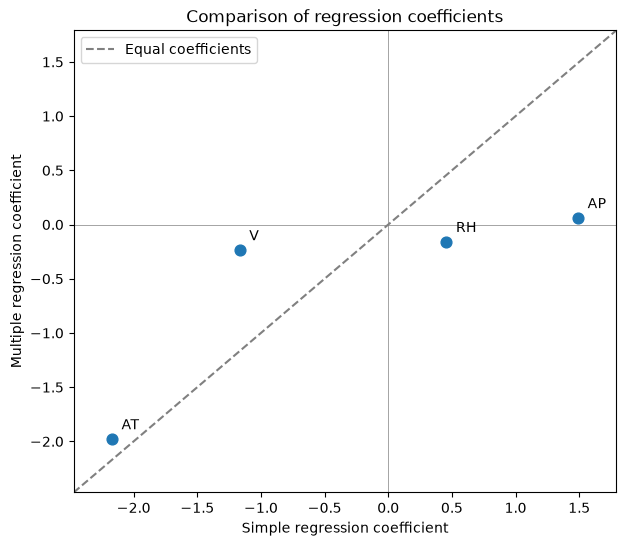

In [8]:
coefficient_comparison = pd.DataFrame({
    "Simple regression": [
        simple_models[feature].params[feature]
        for feature in features
    ],
    "Multiple regression": [
        multiple_model.params[feature]
        for feature in features
    ]
}, index=features)

display(coefficient_comparison)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    coefficient_comparison["Simple regression"],
    coefficient_comparison["Multiple regression"],
    s=60
)

for feature in features:
    x, y = coefficient_comparison.loc[feature]
    ax.annotate(
        feature, (x, y),
        xytext=(7, 7), textcoords="offset points"
    )

limits = [
    coefficient_comparison.to_numpy().min() - 0.3,
    coefficient_comparison.to_numpy().max() + 0.3
]

ax.plot(limits, limits, "--", color="gray", label="Equal coefficients")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set(
    xlabel="Simple regression coefficient",
    ylabel="Multiple regression coefficient",
    title="Comparison of regression coefficients",
    xlim=limits,
    ylim=limits
)
ax.legend()
plt.show()

AT changes relatively little between the two models, from -2.171 to -1.978. The V coefficient moves much closer to zero, from -1.168 to -0.234, and AP drops from 1.490 to 0.062. RH changes sign, from 0.456 to -0.158.

In the coefficient plot, AT is closest to the equal-coefficients line. The other three points show larger changes after the remaining predictors are included.

The predictors are correlated, especially AT and V. A simple regression captures the overall relationship between one predictor and PE, including variation shared with other predictors. Multiple regression adjusts for the other variables. This explains why the coefficients can change in size or even sign.

### (f) Nonlinear Association


AT: centered cubic model


,Coefficient,p-value
Intercept,452.708116,0.000000e+00
x,-2.429734,0.000000e+00
I(x ** 2),0.032554,3.311808e-231
I(x ** 3),0.002675,3.652185e-110



V: centered cubic model


,Coefficient,p-value
Intercept,451.213736,0.000000e+00
x,-1.250257,0.000000e+00
I(x ** 2),0.019177,8.977010e-131
I(x ** 3),0.000134,1.373489e-02



AP: centered cubic model


,Coefficient,p-value
Intercept,453.082345,0.000000e+00
x,1.964663,0.000000e+00
I(x ** 2),0.044238,2.192722e-46
I(x ** 3),-0.004991,2.123338e-67



RH: centered cubic model


,Coefficient,p-value
Intercept,454.442962,0.000000e+00
x,0.530180,9.648727e-152
I(x ** 2),-0.001325,1.013949e-01
I(x ** 3),-0.000152,1.440279e-05


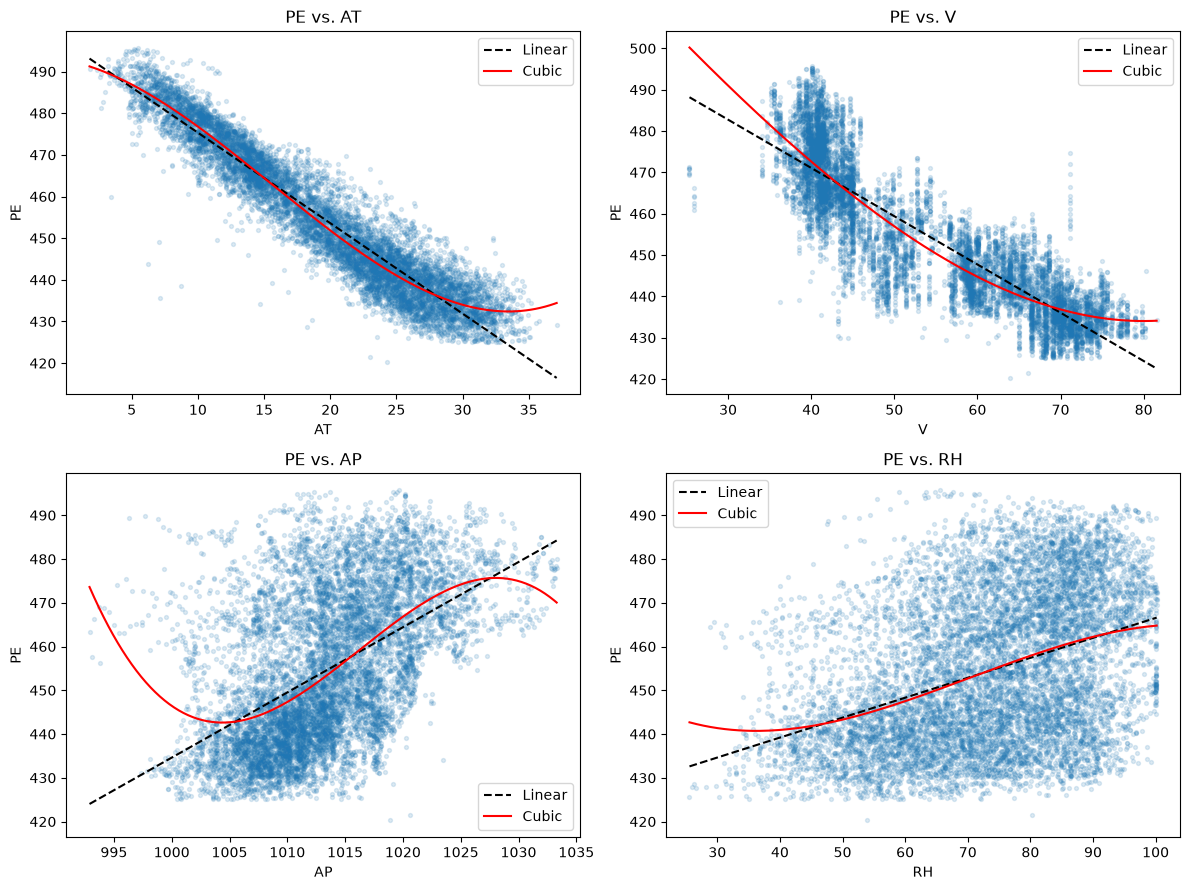

,Linear R-squared,Cubic R-squared,F-statistic,Nonlinearity p-value
Predictor,,,,
AT,0.898948,0.911883,701.967278,3.478379e-285
V,0.756518,0.775022,393.314147,7.040304e-165
AP,0.268769,0.297543,195.885627,4.209145e-84
RH,0.151939,0.153743,10.188863,3.799622e-05


In [9]:
nonlinear_results = []
cubic_models = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flat, features):
    feature_mean = df[feature].mean()

    centered_data = pd.DataFrame({
        "PE": df["PE"],
        "x": df[feature] - feature_mean
    })

    linear_model = smf.ols("PE ~ x", data=centered_data).fit()
    cubic_model = smf.ols(
        "PE ~ x + I(x ** 2) + I(x ** 3)",
        data=centered_data
    ).fit()

    cubic_models[feature] = cubic_model

    f_stat, p_value, _ = cubic_model.compare_f_test(linear_model)

    nonlinear_results.append({
        "Predictor": feature,
        "Linear R-squared": linear_model.rsquared,
        "Cubic R-squared": cubic_model.rsquared,
        "F-statistic": f_stat,
        "Nonlinearity p-value": p_value
    })

    print(f"\n{feature}: centered cubic model")
    display(pd.DataFrame({
        "Coefficient": cubic_model.params,
        "p-value": cubic_model.pvalues
    }))

    x_grid = np.linspace(df[feature].min(), df[feature].max(), 200)
    prediction_data = pd.DataFrame({"x": x_grid - feature_mean})

    ax.scatter(df[feature], df["PE"], s=8, alpha=0.15)
    ax.plot(
        x_grid, linear_model.predict(prediction_data),
        color="black", linestyle="--", label="Linear"
    )
    ax.plot(
        x_grid, cubic_model.predict(prediction_data),
        color="red", label="Cubic"
    )
    ax.set(xlabel=feature, ylabel="PE", title=f"PE vs. {feature}")
    ax.legend()

plt.tight_layout()
plt.show()

nonlinear_results = pd.DataFrame(nonlinear_results).set_index("Predictor")
display(nonlinear_results)

I centered each predictor before taking its second and third powers to reduce numerical problems, especially for AP. This changes the coefficient values but preserves the set of curves the cubic model can fit.

The F-tests compare each cubic model with its linear model by testing whether the quadratic and cubic coefficients are jointly zero. The p-values are approximately 3.48e-285 for AT, 7.04e-165 for V, 4.21e-84 for AP, and 3.80e-5 for RH. All are below 0.05, so there is evidence of nonlinearity for all four predictors.

The fitted curves flatten at high AT and V values, where the straight lines continue downward. R-squared rises from 0.899 to 0.912 for AT, 0.757 to 0.775 for V, and 0.269 to 0.298 for AP. RH improves only from 0.152 to 0.154, so its statistically significant nonlinearity adds little to the overall fit. In the centered RH model, the quadratic term alone is not significant (p = 0.101), but the cubic term is significant (p = 1.44e-5), consistent with the joint test.

### (g) Interactions of Predictors

In [10]:
interaction_model = smf.ols(
    "PE ~ (AT + V + AP + RH) ** 2",
    data=df
).fit()

all_results = pd.DataFrame({
    "Coefficient": interaction_model.params,
    "p-value": interaction_model.pvalues
})

display(all_results)

interaction_results = all_results[
    all_results.index.str.contains(":")
].copy()

interaction_results["Significant at 0.05"] = (
    interaction_results["p-value"] < 0.05
)

display(interaction_results)
print(f"R-squared: {interaction_model.rsquared:.4f}")

,Coefficient,p-value
Intercept,685.782468,3.231607e-18
AT,-4.347014,6.701873e-02
V,-7.674858,1.371251e-08
AP,-0.152355,4.735732e-02
RH,1.570907,4.225213e-02
AT:V,0.020971,3.333358e-117
AT:AP,0.001759,4.520509e-01
AT:RH,-0.005230,1.216944e-10
V:AP,0.006812,2.877026e-07
V:RH,0.000839,8.619366e-02


,Coefficient,p-value,Significant at 0.05
AT:V,0.020971,3.333358e-117,True
AT:AP,0.001759,4.520509e-01,False
AT:RH,-0.005230,1.216944e-10,True
V:AP,0.006812,2.877026e-07,True
V:RH,0.000839,8.619366e-02,False
AP:RH,-0.001612,3.360557e-02,True


R-squared: 0.9363


Four of the six interaction terms are significant at the 0.05 level: AT:V, AT:RH, V:AP, and AP:RH. The p-value for AP:RH is about 0.034; the other three are much smaller. AT:AP and V:RH are not significant, with p-values of about 0.452 and 0.086.

These terms allow the estimated relationship between a predictor and PE to depend on another predictor. For example, the positive AT:V coefficient of 0.02097 means that, with AP and RH fixed, each one-unit increase in V raises the estimated AT slope by 0.02097.

R-squared increases from 0.9287 in the model without interactions to 0.9363. This improves the fit to the current data, but test error is still needed to compare predictive performance.

### (h) Improvement

In [11]:
# Use the same split for all model comparisons in (h)-(j).
train_df, test_df = train_test_split(df, test_size=0.30, random_state=42)
print(f"Training observations: {len(train_df)}")
print(f"Test observations: {len(test_df)}")

baseline_model = smf.ols("PE ~ AT + V + AP + RH", data=train_df).fit()

# Center using training means, then apply the same transformation to test data.
training_means = train_df[features].mean()
train_centered = train_df.copy()
test_centered = test_df.copy()
train_centered[features] = train_df[features] - training_means
test_centered[features] = test_df[features] - training_means

square_terms = {f"I({x} ** 2)": {x} for x in features}
interaction_terms = {f"{a}:{b}": {a, b} for a, b in combinations(features, 2)}
parents = {**square_terms, **interaction_terms}
active_terms = features + list(square_terms) + list(interaction_terms)
removed_terms = []
alpha = 0.05

# Backward elimination with strong hierarchy: retain a main effect while
# any square or interaction involving that predictor remains in the model.
while True:
    formula = "PE ~ " + " + ".join(active_terms)
    improved_model = smf.ols(formula, data=train_centered).fit()
    removable = []
    for term in active_terms:
        if term in features:
            has_child = any(
                term in parents.get(other, set()) for other in active_terms
            )
            if has_child:
                continue
        removable.append(term)

    if not removable:
        break
    p_values = improved_model.pvalues.loc[removable]
    worst_term = p_values.idxmax()
    if p_values[worst_term] <= alpha:
        break
    removed_terms.append({"Removed term": worst_term,
                          "p-value at removal": p_values[worst_term]})
    active_terms.remove(worst_term)

print("Removed terms:")
display(pd.DataFrame(removed_terms))
print("Final formula (centered predictors):", improved_model.model.formula)
display(pd.DataFrame({"Coefficient": improved_model.params,
                      "p-value": improved_model.pvalues}))

linear_scores = pd.DataFrame([
    {
        "Model": "Multiple linear regression",
        "Train MSE": mean_squared_error(train_df["PE"], baseline_model.predict(train_df)),
        "Test MSE": mean_squared_error(test_df["PE"], baseline_model.predict(test_df))
    },
    {
        "Model": "Selected quadratic and interaction regression",
        "Train MSE": mean_squared_error(train_df["PE"], improved_model.predict(train_centered)),
        "Test MSE": mean_squared_error(test_df["PE"], improved_model.predict(test_centered))
    }
]).set_index("Model")
display(linear_scores)

Training observations: 6697
Test observations: 2871
Removed terms:


,Removed term,p-value at removal
0,V:RH,0.867382
1,I(V ** 2),0.607733
2,V:AP,0.357826


Final formula (centered predictors): PE ~ AT + V + AP + RH + I(AT ** 2) + I(AP ** 2) + I(RH ** 2) + AT:V + AT:AP + AT:RH + AP:RH


,Coefficient,p-value
Intercept,453.227507,0.000000e+00
AT,-1.817267,0.000000e+00
V,-0.298531,9.368828e-229
AP,0.116926,7.640325e-24
RH,-0.125096,9.287314e-127
I(AT ** 2),0.019534,5.853797e-16
I(AP ** 2),-0.007644,1.073202e-08
I(RH ** 2),-0.001940,2.022482e-12
AT:V,0.008246,1.547742e-08
AT:AP,0.006975,1.507773e-03


,Train MSE,Test MSE
Model,,
Multiple linear regression,20.580840,21.239857
Selected quadratic and interaction regression,17.890843,18.660040


I used 6,697 observations for training and 2,871 for testing, with random_state=42 so the split can be reproduced. The expanded model started with all four predictors, their squares, and all six pairwise interactions. I removed terms with p-values above 0.05 using only the training data, while keeping the main effects required by any remaining square or interaction.

The procedure removed V:RH, V squared, and V:AP, in that order. The final model retained all four main effects, the squares of AT, AP, and RH, and the interactions AT:V, AT:AP, AT:RH, and AP:RH. The selected terms differ from part (g) because this model also includes squares and is fitted on the training subset.

The ordinary multiple regression has a training MSE of 20.581 and a test MSE of 21.240. The selected model reduces these to 17.891 and 18.660. Both errors decrease, so adding the selected nonlinear and interaction terms improves prediction on this split.

### (i) KNN

,k,Train MSE,Test MSE
Features,,,
Raw,5,10.600769,15.726820
Normalized,4,8.454348,14.291333


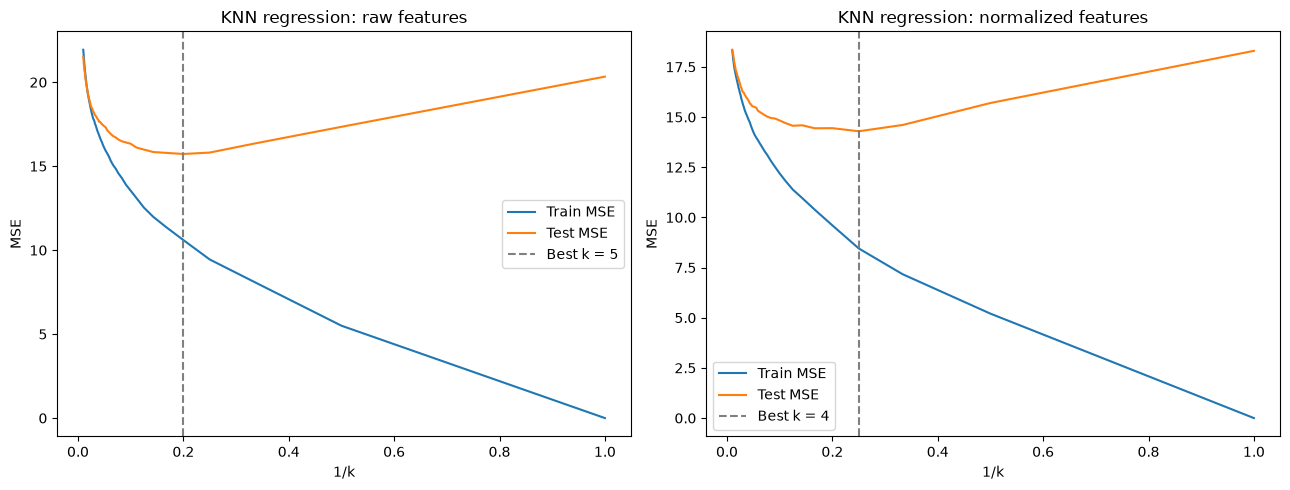

Best k is selected by the lowest test MSE in this homework sweep.
Because this set is used to choose k, its error is not an independent final estimate.


In [12]:
X_train = train_df[features]
X_test = test_df[features]
y_train = train_df["PE"]
y_test = test_df["PE"]

# Fit the normalization on training data only.
scaler = MinMaxScaler()
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)

feature_sets = {
    "Raw": (X_train, X_test),
    "Normalized": (X_train_normalized, X_test_normalized)
}
knn_rows = []

for label, (train_x, test_x) in feature_sets.items():
    for k in range(1, 101):
        model = KNeighborsRegressor(
            n_neighbors=k, weights="uniform", metric="euclidean",
            algorithm="kd_tree"
        )
        model.fit(train_x, y_train)
        knn_rows.append({
            "Features": label,
            "k": k,
            "1/k": 1 / k,
            "Train MSE": mean_squared_error(y_train, model.predict(train_x)),
            "Test MSE": mean_squared_error(y_test, model.predict(test_x))
        })

knn_results = pd.DataFrame(knn_rows)
best_indices = knn_results.groupby("Features", sort=False)["Test MSE"].idxmin()
best_knn = knn_results.loc[best_indices].set_index("Features")
display(best_knn[["k", "Train MSE", "Test MSE"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, label in zip(axes, feature_sets):
    scores = knn_results[knn_results["Features"] == label].sort_values("1/k")
    ax.plot(scores["1/k"], scores["Train MSE"], label="Train MSE")
    ax.plot(scores["1/k"], scores["Test MSE"], label="Test MSE")
    best_k = int(best_knn.loc[label, "k"])
    ax.axvline(1 / best_k, color="gray", linestyle="--", label=f"Best k = {best_k}")
    ax.set(xlabel="1/k", ylabel="MSE", title=f"KNN regression: {label.lower()} features")
    ax.legend()
plt.tight_layout()
plt.show()

print("Best k is selected by the lowest test MSE in this homework sweep.")
print("Because this set is used to choose k, its error is not an independent final estimate.")

I fitted KNN regression for every K from 1 to 100, using the same training and test observations as in part (h). For the normalized version, I scaled each predictor using its training minimum and maximum, then applied that transformation to the test data.

With raw features, K=5 gives the lowest test MSE, 15.727, with a training MSE of 10.601. With normalized features, the best K is 4, giving a test MSE of 14.291 and a training MSE of 8.454. Normalization improves the best test result here. Since KNN uses distances, changing the feature scales changes which observations are treated as neighbors.

The plots use 1/K on the horizontal axis as requested. Values near the right edge represent smaller neighborhoods and more flexible fits. Training error becomes very small at K=1, but the best test results occur at K=4 or K=5.

I selected K using the lowest test MSE in this sweep. That makes the test set part of model selection, so the reported minimum is not an independent estimate of final performance. A separate validation set or cross-validation would be needed to select K while reserving an untouched test set.

### (j ) Compare KNN and Linear

In [13]:
best_linear_name = linear_scores["Test MSE"].idxmin()
comparison_rows = [{
    "Model": best_linear_name,
    "Train MSE": linear_scores.loc[best_linear_name, "Train MSE"],
    "Test MSE": linear_scores.loc[best_linear_name, "Test MSE"]
}]

for label, row in best_knn.iterrows():
    comparison_rows.append({
        "Model": f"KNN ({label.lower()}, k={int(row['k'])})",
        "Train MSE": row["Train MSE"],
        "Test MSE": row["Test MSE"]
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(model_comparison.sort_values("Test MSE"))

best_knn_label = best_knn["Test MSE"].idxmin()
linear_test_mse = linear_scores.loc[best_linear_name, "Test MSE"]
knn_test_mse = best_knn.loc[best_knn_label, "Test MSE"]
relative_reduction = 100 * (linear_test_mse - knn_test_mse) / linear_test_mse
print(f"Lowest observed test MSE: {model_comparison['Test MSE'].idxmin()}")
print(f"KNN test MSE reduction relative to the best regression model: {relative_reduction:.2f}%")

,Train MSE,Test MSE
Model,,
"KNN (normalized, k=4)",8.454348,14.291333
"KNN (raw, k=5)",10.600769,15.726820
Selected quadratic and interaction regression,17.890843,18.660040


Lowest observed test MSE: KNN (normalized, k=4)
KNN test MSE reduction relative to the best regression model: 23.41%


The selected quadratic and interaction regression is the better of the two regression models evaluated on the held-out data, with a test MSE of 18.660. Both KNN versions do better on this split: raw-feature KNN has a test MSE of 15.727, and normalized KNN has a test MSE of 14.291.

Normalized KNN with K=4 has the lowest observed test error, about 23.41% below the selected regression model. Its local predictions can follow patterns that the chosen global regression equation misses. The regression model is easier to summarize through its coefficients, while KNN predictions depend on nearby training observations.

This comparison is specific to the split and feature scaling used here. Since K was chosen from the test-error curves, an independent test set would be needed to confirm the size of the improvement.

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

A flexible method would generally perform better. With many observations and few predictors, there is enough data to estimate a more complex relationship without as much risk of overfitting.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

A flexible method would generally perform worse. With many predictors and few observations, it can fit accidental patterns in the training data. A less flexible method is more likely to generalize well.

### (c) The relationship between the predictors and response is highly non-linear.

A flexible method would generally perform better because it can follow the nonlinear relationship. An inflexible model may miss that shape and have high bias.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

A flexible method would generally perform worse. When the error variance is very high, extra flexibility can fit noise that will not repeat in new observations. A simpler model can reduce that added variance, although neither model can remove the irreducible error.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [14]:
# ISLR, first edition, Section 2.4, Exercise 7 (printed page 53).
toy_data = pd.DataFrame({
    "Observation": [1, 2, 3, 4, 5, 6],
    "X1": [0, 2, 0, 0, -1, 1],
    "X2": [3, 0, 1, 1, 0, 1],
    "X3": [0, 0, 3, 2, 1, 1],
    "Y": ["Red", "Red", "Red", "Green", "Green", "Red"]
}).set_index("Observation")

toy_features = ["X1", "X2", "X3"]
test_point = pd.DataFrame([[0, 0, 0]], columns=toy_features)
toy_data["Distance"] = np.linalg.norm(
    toy_data[toy_features].to_numpy() - test_point.to_numpy(), axis=1
)
display(toy_data)
neighbor_order = toy_data.sort_values("Distance")
print("Nearest to farthest:", neighbor_order.index.tolist())

,X1,X2,X3,Y,Distance
Observation,,,,,
1,0,3,0,Red,3.000000
2,2,0,0,Red,2.000000
3,0,1,3,Red,3.162278
4,0,1,2,Green,2.236068
5,-1,0,1,Green,1.414214
6,1,1,1,Red,1.732051


Nearest to farthest: [5, 6, 2, 4, 1, 3]


For the test point at the origin, the Euclidean distance is $d=\sqrt{X_1^2+X_2^2+X_3^2}$.

The distances for observations 1 through 6 are $3$, $2$, $\sqrt{10}$, $\sqrt{5}$, $\sqrt{2}$, and $\sqrt{3}$, respectively. From nearest to farthest, the observations are 5, 6, 2, 4, 1, and 3.

### (b) What is our prediction with K = 1? Why?

In [15]:
classifier_1 = KNeighborsClassifier(n_neighbors=1, metric="euclidean")
classifier_1.fit(toy_data[toy_features], toy_data["Y"])
display(neighbor_order.head(1))
print("Prediction for K = 1:", classifier_1.predict(test_point)[0])

,X1,X2,X3,Y,Distance
Observation,,,,,
5,-1,0,1,Green,1.414214


Prediction for K = 1: Green


With K=1, the prediction is Green. Observation 5 is the closest point, at distance $\sqrt{2}$, and its label is Green.

### (c) What is our prediction with K = 3? Why?

In [16]:
classifier_3 = KNeighborsClassifier(n_neighbors=3, metric="euclidean")
classifier_3.fit(toy_data[toy_features], toy_data["Y"])
display(neighbor_order.head(3))
print("Votes:")
display(neighbor_order.head(3)["Y"].value_counts())
print("Prediction for K = 3:", classifier_3.predict(test_point)[0])

,X1,X2,X3,Y,Distance
Observation,,,,,
5,-1,0,1,Green,1.414214
6,1,1,1,Red,1.732051
2,2,0,0,Red,2.000000


Votes:


Y
Red      2
Green    1
Name: count, dtype: int64

Prediction for K = 3: Red


With K=3, the prediction is Red. The nearest observations are 5, 6, and 2, with labels Green, Red, and Red. Red receives two of the three votes.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

A smaller K is generally preferable for a highly nonlinear Bayes decision boundary. It uses a more local neighborhood and can follow changes in the boundary. A large K smooths over those changes. The best K need not be 1, since very small neighborhoods can also be sensitive to noise.

### References

- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, first edition, Section 2.4, Exercises 1 and 7, printed pages 52-54. [Official textbook PDF](https://www.statlearning.com/s/ISLRSeventhPrinting.pdf).

### AI assistance

I used OpenAI Codex for Python function usage queries and example code references. Codex also helped draft code and written explanations, including completing sections (h)-(j) and the ISLR exercises. The completed notebook was executed to check the code and outputs.

Example prompts (translated into English): "Include code and analysis" and "Complete the remaining code."
